# Hafta 6 — Sınıf Dengesizliği ve Eşik Seçimi

Stratejiler `src/modeling.py` (`build_model`), eşik seçimi `src/threshold.py` içindedir. Rapordaki sayıların kaynağı `notebooks/build_dengesizlik.py` ile üretilen `hafta6_ozet.json` dosyasıdır (3 model × 3 strateji). Bu notebook yalnızca XGBoost ile yöntemi gösterir. Test seti ayrılır ama hiçbir hücrede kullanılmaz.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from src.data_loader import load_raw
from src.evaluate import summarize_cv
from src.model_plots import plot_threshold_curves
from src.modeling import IMBALANCE_STRATEGIES, STRATEGY_LABELS, build_model, cross_validate_model, make_cv
from src.preprocessing import split_train_test
from src.threshold import select_threshold_for_recall, select_threshold_max_f1

split = split_train_test(load_raw())
print('eğitim:', split.X_train.shape, 'test:', split.X_test.shape)

eğitim: (36168, 15) test: (9043, 15)


## 1. XGBoost, üç strateji, aynı 5 katlı CV

In [2]:
cv = make_cv()
results = {s: cross_validate_model(build_model('xgboost', s), split.X_train, split.y_train, cv) for s in IMBALANCE_STRATEGIES}
pd.concat({STRATEGY_LABELS[s]: summarize_cv(r.fold_metrics) for s, r in results.items()}, axis=1).round(4)

Ağırlıksız         Sınıf ağırlığı           SMOTE        
                mean     std           mean     std    mean     std
accuracy      0.8948  0.0029         0.8230  0.0079  0.8944  0.0017
precision     0.6329  0.0308         0.3539  0.0133  0.6316  0.0160
recall        0.2392  0.0175         0.6192  0.0048  0.2340  0.0139
f1            0.3471  0.0225         0.4503  0.0106  0.3414  0.0164
roc_auc       0.8011  0.0021         0.7968  0.0015  0.7993  0.0037
pr_auc        0.4532  0.0135         0.4466  0.0146  0.4498  0.0145

## 2. Eşik, yalnızca OOF tahminlerinden seçilir

ThresholdChoice(threshold=0.21514949202537537, precision=0.4713973799126638, recall=0.5102812573859608, f1=0.49006923164226535, criterion='max_f1')
ThresholdChoice(threshold=0.09857144951820374, precision=0.28690430065865946, recall=0.7000709052233515, f1=0.4070079010649262, criterion='target_recall')


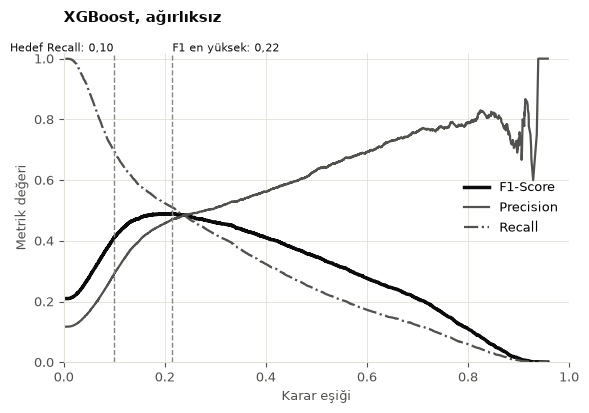

In [3]:
oof = results['none'].oof_proba
f1_choice = select_threshold_max_f1(split.y_train, oof)
recall_choice = select_threshold_for_recall(split.y_train, oof)
print(f1_choice)
print(recall_choice)
plot_threshold_curves(split.y_train, oof, f1_choice, recall_choice, 'XGBoost, ağırlıksız');